In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import os

import testis_model as tm
from analysis import color_map

In [2]:
from analysis import small_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [3]:
experiment = 'full_pipeline'
file = f'../experiments/{experiment}/final_data.csv'
df = pd.read_csv(file)

#remove controls
df = df[~df['fish'].str.contains('fishctrl|fishwater', case=False, regex=True, na=False)]

# Convert sample number to time
df['time'] = df['sample'].map(tm.data_processing.sample_map_int)

# Figure 1E

In [4]:
barcode_counts = (
    df.query('sample == 1').groupby('fish')['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

unique_fish = sorted(df['fish'].unique())

In [5]:
# Order fish numerically for legend
# Extract numeric part and sort using raw string
barcode_counts['fish_num'] = barcode_counts['fish'].str.extract(r'(\d+)').astype(int)
barcode_counts = barcode_counts.sort_values('fish_num')
barcode_counts.head()

,fish,unique_barcode_count,fish_num
0,fish1,8,1
6,fish2,4,2
14,fish5,7,5
15,fish8,10,8
1,fish10,2,10


In [6]:
# Create ordered categorical for proper legend ordering
fish_order = barcode_counts.sort_values('fish_num')['fish'].tolist()
barcode_counts['fish'] = pd.Categorical(barcode_counts['fish'], categories=fish_order, ordered=True)

median_value = barcode_counts['unique_barcode_count'].median()
print(f'The median number of barcodes is {median_value}.')

The median number of barcodes is 9.0.


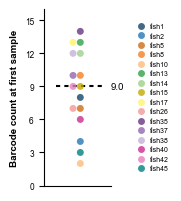

In [7]:
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(1.7, 1.9), constrained_layout = True) #height 2.27 for Fig.1
sns.swarmplot(
    data=barcode_counts,
    x=[0] * len(barcode_counts),
    y='unique_barcode_count',
    hue='fish',
    palette=color_map,
    alpha=0.8,
    ax=ax,
    dodge=False,
    hue_order=fish_order
)

# Add legend with proper ordering
ax.legend(
    title = None,
    bbox_to_anchor=(1.25, 0.5),
    loc='center left',
    frameon=False,
    fontsize=5,
    title_fontsize=7,
    columnspacing=0.5,
    handletextpad=0.3
)

ax.hlines(y=median_value, xmin=-0.2, xmax=0.2, color='black', linewidth=1.5, linestyle=(0, (2, 2)))
ax.text(0.25, median_value, f"{median_value}",
        va='center', ha='left', fontsize=7, color='black')
ax.set_xlim(-0.3, 0.25)
ax.set_ylim(0, 16)

ax.set_yticks([0, 3, 6, 9, 12, 15])
ax.set_yticklabels([0, 3, 6, 9, 12, 15], fontsize=6)

ax.set_ylabel("Barcode count at first sample", fontsize=7, fontweight = 'bold')
ax.set_xticks([])
ax.set_xlabel('')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)

plt.savefig("images/barcode_counts/barcode_counts_s1.svg", bbox_inches='tight', transparent=True)
plt.savefig("images/barcode_counts/barcode_counts_s1.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [8]:
counts = barcode_counts['unique_barcode_count']

stats = {
    'N':        len(counts),
    'Mean':     counts.mean(),
    'Median':   counts.median(),
    'Std Dev':  counts.std(),
    'Range':    f"{counts.min()} – {counts.max()}",
    'Min':      counts.min(),
    'Max':      counts.max(),
}

print("  Unique Barcodes per Fish — Summary")
print("=" * 38)
for k, v in stats.items():
    if isinstance(v, float):
        print(f"  {k:<12} {v:.3f}")
    else:
        print(f"  {k:<12} {v}")

  Unique Barcodes per Fish — Summary
  N            16
  Mean         8.688
  Median       9.000
  Std Dev      3.683
  Range        2 – 14
  Min          2
  Max          14


# Figure 2G

In [9]:
barcode_counts = (
    df.groupby('fish')['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

unique_fish = sorted(df['fish'].unique())

In [10]:
barcode_counts['fish_num'] = barcode_counts['fish'].str.extract(r'(\d+)').astype(int)
barcode_counts = barcode_counts.sort_values('fish_num')
barcode_counts.head()

,fish,unique_barcode_count,fish_num
0,fish1,12,1
9,fish2,7,2
15,fish4,7,4
20,fish5,10,5
23,fish8,11,8


In [11]:
# Create ordered categorical for proper legend ordering
fish_order = barcode_counts.sort_values('fish_num')['fish'].tolist()
barcode_counts['fish'] = pd.Categorical(barcode_counts['fish'], categories=fish_order, ordered=True)

median_value = barcode_counts['unique_barcode_count'].median()
print(f'The median number of barcodes is {median_value}.')

The median number of barcodes is 11.5.


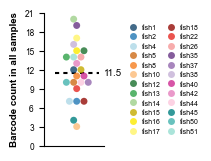

In [13]:
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(2, 1.5), constrained_layout = True) #height 2.27 for Fig.1
sns.swarmplot(
    data=barcode_counts,
    x=[0] * len(barcode_counts),
    y='unique_barcode_count',
    hue='fish',
    palette=color_map,
    alpha=0.8,
    ax=ax,
    dodge=False,
    hue_order=fish_order
)

# Add legend with proper ordering
ax.legend(
    title = None,
    bbox_to_anchor=(1.25, 0.5),
    loc='center left',
    frameon=False,
    fontsize=5,
    title_fontsize=7,
    columnspacing=0.5,
    handletextpad=0.3,
    ncol = 2
)
# OR: remove legend 
# ax.legend_.remove()

ax.hlines(y=median_value, xmin=-0.2, xmax=0.2, color='black', linestyle=(0, (2, 2)), linewidth=1.5)
ax.text(0.25, median_value, f"{median_value}",
        va='center', ha='left', fontsize=7, color='black')
ax.set_xlim(-0.3, 0.25)
ax.set_ylim(0, 16)

# For t1 summary in main figure: Set y-axis ticks from 0 to 15
# For ALL TIME summary in supplement: Set y-axis ticks from 0 to 21
ax.set_yticks([0, 3, 6, 9, 12, 15, 18, 21])
ax.set_yticklabels([0, 3, 6, 9, 12, 15, 18, 21])

ax.set_ylabel("Barcode count in all samples", fontweight = 'bold')
ax.set_xticks([])
ax.set_xlabel('')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
# ax.spines['left'].set_linewidth(1.5)
# ax.plot([-0.3, 0.25], [0, 0], color='black', linewidth=1.5, clip_on=False)

plt.savefig("images/barcode_counts/barcode_counts.svg", bbox_inches='tight', transparent=True)
plt.savefig("images/barcode_counts/barcode_counts.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [14]:
counts = barcode_counts['unique_barcode_count']

stats = {
    'N':        len(counts),
    'Mean':     counts.mean(),
    'Median':   counts.median(),
    'Std Dev':  counts.std(),
    'Range':    f"{counts.min()} – {counts.max()}",
    'Min':      counts.min(),
    'Max':      counts.max(),
}

print("  Unique Barcodes per Fish — Summary")
print("=" * 38)
for k, v in stats.items():
    if isinstance(v, float):
        print(f"  {k:<12} {v:.3f}")
    else:
        print(f"  {k:<12} {v}")

  Unique Barcodes per Fish — Summary
  N            24
  Mean         11.667
  Median       11.500
  Std Dev      4.320
  Range        3 – 20
  Min          3
  Max          20
